# Spectral (signed SVD) embeddings of members
**Embedding.** Signed vote matrix `V[member, bill]`: Yea = +1, Nay = -1, absent / present = 0 (no relation). Each bill column is centered over the members who actually voted, absences stay 0, and we take an SVD. Member coordinates = `U * s / sqrt(votes cast)`. This is a deterministic, Nay-aware cousin of node2vec and an IRT-style multi-dimensional ideal point.

**Comparability problem.** Each Congress is embedded separately, so the rotation (and the sign of axes 2+) is arbitrary and raw coordinates cannot be pooled across Congresses. We therefore use only features that are invariant to that: the party-oriented 1st axis, magnitudes (|axis 2|, norm of the remaining axes), distances to the member's own / other party centroid in the k-dim space, and within-party rank on axis 1 (how far toward the other side).

**Benchmark.** Voteview's DW-NOMINATE coordinates are computed jointly across Congresses and are comparable; we build the same features from them.

Setup as before: train 115/116, test 118 (117 set aside); target `tilt` (and `tilt_c`, the party-year-demeaned version).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
TRAIN, TEST = [115, 116], 118
CONGS = TRAIN + [TEST]
MIN_VOTES = 20

In [2]:
def load(c):
    mem = pd.read_csv(f"data/{c}/voteview/H{c}_members.csv")
    mem = mem[(mem.chamber == "House") & mem.bioguide_id.notna()].drop_duplicates("bioguide_id")
    bills = pd.read_csv(f"data/{c}/bills.csv")[["bill_number", "rollnumber"]]
    votes = pd.read_csv(f"data/{c}/voteview/H{c}_votes.csv")
    votes = votes[votes.chamber == "House"].merge(bills, on="rollnumber")
    votes["v"] = votes.cast_code.map({1: 1, 2: 1, 3: 1, 4: -1, 5: -1, 6: -1}).fillna(0)
    V = (votes.pivot_table(index="icpsr", columns="bill_number", values="v", aggfunc="first")
         .reindex(index=mem.icpsr, columns=bills.bill_number).fillna(0))
    V.index = mem.bioguide_id.values
    meta = pd.DataFrame({"party": mem.party_code.map({100: "D", 200: "R"}).fillna("O").values,
                         "nom1": mem.nominate_dim1.values, "nom2": mem.nominate_dim2.values}, index=V.index)
    return V, meta

V, meta = {}, {}
for c in CONGS:
    V[c], meta[c] = load(c)
    print(c, V[c].shape, "members with DW-NOMINATE:", meta[c].nom1.notna().sum())

115 (450, 429) members with DW-NOMINATE: 450


116 (448, 273) members with DW-NOMINATE: 447


118 (451, 360) members with DW-NOMINATE: 451


## 1. Signed SVD

In [3]:
def spectral(c, k=10):
    Vv = V[c].values; P = Vv != 0
    n = P.sum(1)
    mu = Vv.sum(0) / np.maximum(P.sum(0), 1)                     # mean vote among those who voted
    X = np.where(P, Vv - mu, 0.0)
    ok = n >= MIN_VOTES
    U, s, _ = np.linalg.svd(X[ok], full_matrices=False)
    emb = np.full((len(Vv), k), np.nan)
    emb[ok] = (U[:, :k] * s[:k]) / np.sqrt(n[ok])[:, None]
    p = meta[c].party.values
    if np.nanmean(emb[p == "R", 0]) < np.nanmean(emb[p == "D", 0]): emb[:, 0] *= -1      # orient axis 1: R positive
    return emb, s ** 2 / (s ** 2).sum()

emb, evr = {}, {}
for c in CONGS:
    emb[c], evr[c] = spectral(c)
    both = meta[c].nom1.notna().values & ~np.isnan(emb[c][:, 0])
    print(c, "variance explained by axes 1-5:", evr[c][:5].round(3), "| corr(axis1, DW-NOM1) = %.3f" % pearsonr(emb[c][both, 0], meta[c].nom1.values[both])[0],
          "| corr(axis2, DW-NOM2) = %.3f" % abs(pearsonr(emb[c][both, 1], meta[c].nom2.values[both])[0]))

115 variance explained by axes 1-5: [0.696 0.039 0.023 0.01  0.009] | corr(axis1, DW-NOM1) = 0.951 | corr(axis2, DW-NOM2) = 0.565
116 variance explained by axes 1-5: [0.694 0.05  0.015 0.014 0.009] | corr(axis1, DW-NOM1) = 0.974 | corr(axis2, DW-NOM2) = 0.513


118 variance explained by axes 1-5: [0.649 0.081 0.031 0.014 0.011] | corr(axis1, DW-NOM1) = 0.965 | corr(axis2, DW-NOM2) = 0.701


## 2. Rotation-invariant features from the embedding (and from DW-NOMINATE)

In [4]:
def geom_feats(E, party, prefix):
    """E: (n, k) coordinates with NaN for members without enough votes. Features invariant to rotation of axes 2+."""
    D, R = party == "D", party == "R"
    ok = ~np.isnan(E[:, 0])
    cD, cR = E[D & ok].mean(0), E[R & ok].mean(0)
    own, oth = np.where(D[:, None], cD, cR), np.where(D[:, None], cR, cD)
    d_own, d_oth = np.linalg.norm(E - own, axis=1), np.linalg.norm(E - oth, axis=1)
    out = pd.DataFrame({"axis1": E[:, 0], "d_own": d_own, "d_oth": d_oth, "rel_d": d_own / (d_own + d_oth)})
    if E.shape[1] > 1: out["abs_axis2"] = np.abs(E[:, 1])
    if E.shape[1] > 2: out["rest_norm"] = np.linalg.norm(E[:, 2:], axis=1)
    # within-party rank on axis 1 toward the other party: 1 = most cross-pressured end of own party
    a1 = pd.Series(E[:, 0])
    out["mod_rank"] = np.where(D, a1.where(D & ok).rank(pct=True), np.where(R, (-a1).where(R & ok).rank(pct=True), np.nan))
    return out.add_prefix(prefix)

def all_feats(c):
    p = meta[c].party.values
    parts = [geom_feats(emb[c][:, :k], p, f"sp{k}_") for k in (2, 3, 5, 10)]
    N = meta[c][["nom1", "nom2"]].values.astype(float)
    parts.append(geom_feats(N, p, "nom_"))
    f = pd.concat(parts, axis=1); f.index = V[c].index
    return f

# disloyalty from Nays (as in the text-embedding notebook)
def disloyalty(c):
    v, p = V[c].values, meta[c].party.values
    n_cross, n_line = np.zeros(len(v)), np.zeros(len(v))
    for q in ["D", "R"]:
        m = p == q
        tot, pres = v[m].sum(0), np.abs(v[m]).sum(0)
        line = (pres > 0) & (np.abs(tot) / np.maximum(pres, 1) >= 0.5)
        maj = np.sign(tot)
        n_cross[m] = ((v[m] != 0) & (v[m] != maj) & line).sum(1); n_line[m] = ((v[m] != 0) & line).sum(1)
    return pd.DataFrame({"n_cross": np.log1p(n_cross), "cross_rate": n_cross / np.maximum(n_line, 1)}, index=V[c].index)

feats = pd.concat([pd.concat([all_feats(c), disloyalty(c)], axis=1).assign(congress=c).rename_axis("bioguide").reset_index() for c in CONGS])
G_DIS = ["n_cross", "cross_rate"]
SETS_COLS = {k: [c for c in feats.columns if c.startswith(k)] for k in ["sp2_", "sp3_", "sp5_", "sp10_", "nom_"]}
ALLF = [c for c in feats.columns if c.startswith(("sp", "nom_"))] + G_DIS
print({k: len(v) for k, v in SETS_COLS.items()})

{'sp2_': 6, 'sp3_': 7, 'sp5_': 7, 'sp10_': 7, 'nom_': 6}


## 3. Join to the target; z-score within Congress

In [5]:
targets = pd.read_csv("data/elections/targets.csv")
d = targets.merge(feats, on=["congress", "bioguide"])
d = d[d.tilt.notna() & d.party.isin(["D", "R"])].copy()
d["tilt_c"] = d.tilt - d.groupby(["congress", "party"]).tilt.transform("mean")
d["is_R"] = (d.party == "R").astype(float)
d["prev_share"] = d.prev_two_party_share
z = lambda x: (x - x.mean()) / x.std()
d[ALLF + ["prev_share"]] = d.groupby("congress")[ALLF + ["prev_share"]].transform(z)
d[ALLF] = d[ALLF].fillna(0)
print(d.groupby("congress").size().to_dict(), "rows")

{115: 281, 116: 327, 118: 320} rows


## 4. Univariate: Spearman with `tilt_c` by Congress (3-axis spectral features vs DW-NOMINATE)

In [6]:
rows = []
for f_ in SETS_COLS["sp3_"] + SETS_COLS["nom_"] + G_DIS + ["prev_share"]:
    r = {"feature": f_}
    for c in CONGS:
        s = d[d.congress == c]; r[c] = spearmanr(s[f_], s.tilt_c)[0]
    rows.append(r)
uni = pd.DataFrame(rows).set_index("feature")
uni["same_sign"] = (np.sign(uni[115]) == np.sign(uni[116])) & (np.sign(uni[116]) == np.sign(uni[118]))
uni.round(3)

,115,116,118,same_sign
feature,,,,
sp3_axis1,0.059,-0.137,-0.001,False
sp3_d_own,-0.000,-0.102,-0.042,True
sp3_d_oth,0.023,-0.126,-0.059,False
sp3_rel_d,-0.008,-0.100,-0.032,True
sp3_abs_axis2,-0.002,-0.107,-0.030,True
sp3_rest_norm,0.083,-0.072,-0.017,False
sp3_mod_rank,-0.056,0.072,0.067,False
nom_axis1,0.058,-0.090,0.037,False
nom_d_own,0.021,0.007,-0.060,False


## 5. Models
Ridge (penalty by leave-one-Congress-out on 115/116), scored on 118. Pooled with `is_R`, and separate per party. `oos R2` is vs the training mean.

In [7]:
def ridge(X, y, lam):
    mu, ym = X.mean(0), y.mean()
    beta = np.linalg.solve((X - mu).T @ (X - mu) + lam * np.eye(X.shape[1]), (X - mu).T @ (y - ym))
    return (lambda Xn: ym + (Xn - mu) @ beta), beta

LAMS = [1, 10, 100, 1000, 10000]
def tune_fit(tr_, cols, target):
    cv = {lam: sum(((b[target].values - ridge(a[cols].values, a[target].values, lam)[0](b[cols].values)) ** 2).sum()
                   for a, b in [(tr_[tr_.congress != h], tr_[tr_.congress == h]) for h in TRAIN]) for lam in LAMS}
    lam = min(cv, key=cv.get)
    return ridge(tr_[cols].values, tr_[target].values, lam)[0], lam

tr_all, te = d[d.congress.isin(TRAIN)], d[d.congress == TEST]
def pooled(cols, target):
    f, lam = tune_fit(tr_all, cols, target); p, y = f(te[cols].values), te[target].values
    sse0 = ((y - tr_all[target].mean()) ** 2).sum()
    return 1 - ((y - p) ** 2).sum() / sse0, pearsonr(p, y)[0]

def by_party(cols, target):
    p = np.zeros(len(te)); mus = {}
    for q in ["D", "R"]:
        tr_q = tr_all[tr_all.party == q]; f, _ = tune_fit(tr_q, cols, target)
        m = (te.party == q).values; p[m] = f(te[cols].values[m]); mus[q] = tr_q[target].mean()
    y = te[target].values; sse0 = ((y - tr_all[target].mean()) ** 2).sum()
    r2q = {q: 1 - ((y[(te.party == q).values] - p[(te.party == q).values]) ** 2).sum() / ((y[(te.party == q).values] - mus[q]) ** 2).sum() for q in ["D", "R"]}
    return 1 - ((y - p) ** 2).sum() / sse0, r2q["D"], r2q["R"]

BASE = ["prev_share"] + G_DIS
fsets = {"baseline (prev share + disloyalty)": BASE,
         "+ spectral k=2": BASE + SETS_COLS["sp2_"], "+ spectral k=3": BASE + SETS_COLS["sp3_"],
         "+ spectral k=5": BASE + SETS_COLS["sp5_"], "+ spectral k=10": BASE + SETS_COLS["sp10_"],
         "+ DW-NOMINATE": BASE + SETS_COLS["nom_"], "+ spectral k=3 + DW-NOMINATE": BASE + SETS_COLS["sp3_"] + SETS_COLS["nom_"],
         "spectral k=3 only": SETS_COLS["sp3_"], "DW-NOMINATE only": SETS_COLS["nom_"]}
rows = []
for target in ["tilt_c", "tilt"]:
    for name, cols in fsets.items():
        r2, corr = pooled(["is_R"] + cols, target); both, rd, rr = by_party(cols, target)
        rows.append({"target": target, "features": name, "pooled R2": r2, "pooled corr": corr,
                     "separate R2": both, "D R2": rd, "R R2": rr})
pd.DataFrame(rows).set_index(["target", "features"]).round(3)

pooled R2  pooled corr  separate R2   D R2   R R2
target features                                                                             
tilt_c baseline (prev share + disloyalty)      0.087        0.307        0.096  0.134  0.018
       + spectral k=2                          0.093        0.319        0.035  0.051  0.001
       + spectral k=3                          0.090        0.308        0.034  0.050  0.001
       + spectral k=5                          0.048        0.316        0.035  0.051  0.001
       + spectral k=10                         0.050        0.316        0.037  0.054  0.001
       + DW-NOMINATE                           0.009        0.266        0.090  0.132  0.002
       + spectral k=3 + DW-NOMINATE            0.009        0.268        0.041  0.060  0.002
       spectral k=3 only                      -0.000       -0.022       -0.000 -0.000 -0.001
       DW-NOMINATE only                        0.001        0.102       -0.002 -0.003  0.001
tilt   baseline (prev share + disloyalty)      0.006        0.199        0.051  0.107 -0.000
       + spectral k=2                          0.001        0.035        0.005  0.044  0.001
       + spectral k=3                          0.002        0.048        0.008  0.048 -0.001
       + spectral k=5                          0.002        0.042        0.005  0.044 -0.002
       + spectral k=10                        -0.001        0.013        0.000  0.040 -0.007
       + DW-NOMINATE                           0.006        0.178        0.050  0.106 -0.001
       + spectral k=3 + DW-NOMINATE            0.003        0.060        0.012  0.054 -0.001
       spectral k=3 only                      -0.004       -0.045       -0.026  0.000  0.000
       DW-NOMINATE only                        0.000        0.010       -0.036 -0.013 -0.000

## 6. Pictures: variance explained and the 118th House in the first two axes

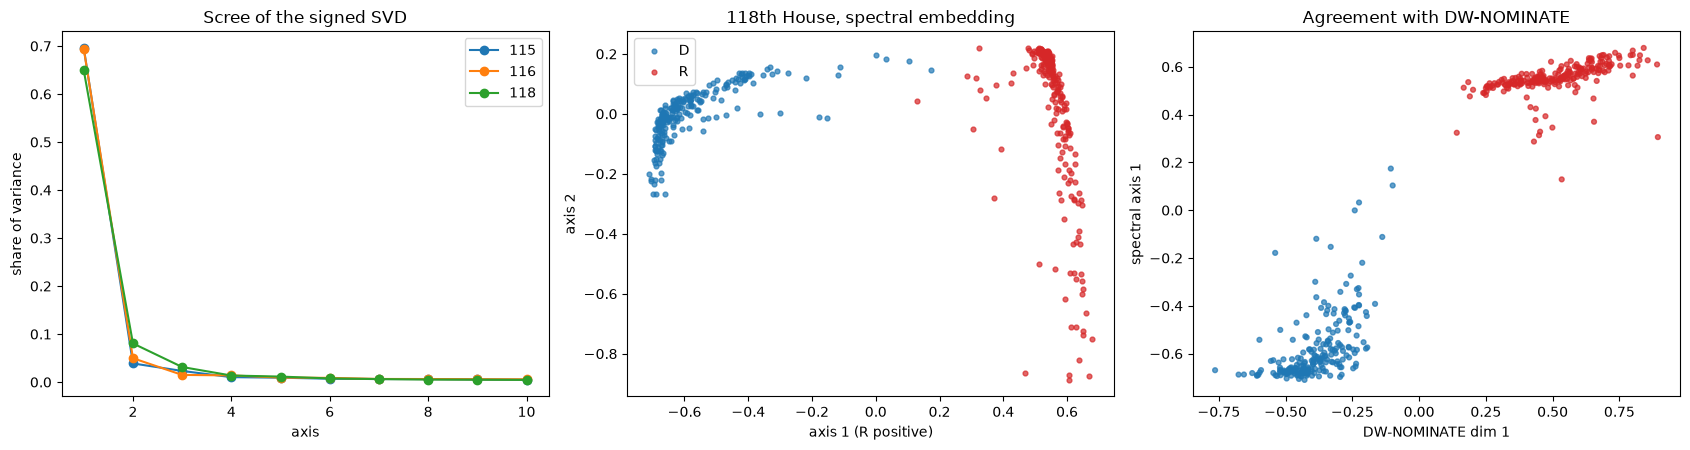

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for c in CONGS: ax[0].plot(range(1, 11), evr[c][:10], marker="o", label=str(c))
ax[0].set(xlabel="axis", ylabel="share of variance", title="Scree of the signed SVD"); ax[0].legend()
c = TEST; E = emb[c]; p = meta[c].party.values; ok = ~np.isnan(E[:, 0])
for q, col in [("D", "#1f77b4"), ("R", "#d62728")]:
    m = ok & (p == q); ax[1].scatter(E[m, 0], E[m, 1], s=12, alpha=0.7, c=col, label=q)
ax[1].set(xlabel="axis 1 (R positive)", ylabel="axis 2", title="118th House, spectral embedding"); ax[1].legend()
both = ok & meta[c].nom1.notna().values
ax[2].scatter(meta[c].nom1.values[both], E[both, 0], s=12, alpha=0.7, c=np.where(p[both] == "R", "#d62728", "#1f77b4"))
ax[2].set(xlabel="DW-NOMINATE dim 1", ylabel="spectral axis 1", title="Agreement with DW-NOMINATE")
plt.tight_layout(); plt.show()

## What we notice
1. **The embedding is essentially one-dimensional.** Axis 1 explains 65-70% of the variance in every Congress (axis 2: 4-8%, the rest 3% or less) and correlates 0.95-0.97 with DW-NOMINATE dim 1. Axis 2 matches DW-NOMINATE dim 2 only moderately (|r| 0.51-0.70).
2. **None of the position features predict tilt.** Univariate signs flip across years for almost every spectral and DW-NOMINATE feature (only `sp3_d_own`, `sp3_rel_d`, `sp3_abs_axis2` keep a sign, and they are near 0 and weak). Disloyalty and prev share remain the only stable ones.
3. **Adding them does not beat the baseline.** `tilt_c` pooled oos R2: baseline 0.087; +spectral k=2 0.093 (not meaningful), k=3 0.090, k=5 0.048, k=10 0.050; +DW-NOMINATE 0.009. On raw `tilt`: all about 0. Separate-per-party fits get worse with spectral features (0.096 -> 0.035) because they add noisy columns for ~160 members per party.
4. **Spectral features alone are 0**; so is DW-NOMINATE alone. Where a member sits ideologically carries essentially no information about over- or under-performing the national swing, once party and previous share are known.
5. **Takeaway.** A richer embedding of the voting graph (node2vec-style, spectral, or text) keeps recovering the same ideology axis we already have; the limit is the target (small sample, mostly local noise), not the representation.

## 7. Ablation: without the disloyalty features
Same comparison as section 5, but the baseline is just `prev_share` (plus party in the pooled model) and disloyalty (`n_cross`, `cross_rate`) is left out everywhere.

In [9]:
BASE0 = ["prev_share"]
fsets0 = {"prev share only": BASE0, "prev share + disloyalty (for reference)": BASE0 + G_DIS,
          "+ spectral k=2": BASE0 + SETS_COLS["sp2_"], "+ spectral k=3": BASE0 + SETS_COLS["sp3_"],
          "+ spectral k=5": BASE0 + SETS_COLS["sp5_"], "+ spectral k=10": BASE0 + SETS_COLS["sp10_"],
          "+ DW-NOMINATE": BASE0 + SETS_COLS["nom_"], "party only": []}
rows = []
for target in ["tilt_c", "tilt"]:
    for name, cols in fsets0.items():
        r2, corr = pooled(["is_R"] + cols, target)
        both, rd, rr = by_party(cols, target) if cols else (np.nan, np.nan, np.nan)
        rows.append({"target": target, "features": name, "pooled R2": r2, "pooled corr": corr,
                     "separate R2": both, "D R2": rd, "R R2": rr})
pd.DataFrame(rows).set_index(["target", "features"]).round(3)

pooled R2  pooled corr  separate R2   D R2   R R2
target features                                                                                  
tilt_c prev share only                              0.077        0.286        0.083  0.111  0.024
       prev share + disloyalty (for reference)      0.087        0.307        0.096  0.134  0.018
       + spectral k=2                               0.082        0.315        0.030  0.045  0.001
       + spectral k=3                               0.041        0.304        0.029  0.043  0.001
       + spectral k=5                               0.007        0.301        0.031  0.046  0.001
       + spectral k=10                              0.047        0.333        0.034  0.050  0.001
       + DW-NOMINATE                                0.008        0.277        0.073  0.107  0.002
       party only                                   0.000        0.000          NaN    NaN    NaN
tilt   prev share only                              0.007        0.272        0.060  0.117  0.004
       prev share + disloyalty (for reference)      0.006        0.199        0.051  0.107 -0.000
       + spectral k=2                               0.002        0.047        0.007  0.045  0.003
       + spectral k=3                               0.003        0.060        0.008  0.048  0.002
       + spectral k=5                               0.003        0.055        0.005  0.044  0.000
       + spectral k=10                              0.000        0.021        0.001  0.040 -0.005
       + DW-NOMINATE                                0.007        0.207        0.058  0.116  0.001
       party only                                  -0.000       -0.084          NaN    NaN    NaN

### Result of section 7 (no disloyalty)
- **Previous share alone carries almost all of it:** `tilt_c` pooled oos R2 0.077 (separate per party 0.083; Democrats 0.111, Republicans 0.024). Adding disloyalty lifts that to 0.087 / 0.096, about +0.01, and on raw `tilt` it does not help (separate 0.060 -> 0.051).
- **Spectral features still add nothing without disloyalty:** `tilt_c` pooled R2 0.082 (k=2), 0.041 (k=3), 0.007 (k=5), 0.047 (k=10) vs 0.077 for prev share alone; separate-per-party fits fall from 0.083 to about 0.03. DW-NOMINATE: 0.008 pooled.
- Raw `tilt`: every variant is within noise of prev share alone (pooled 0.000-0.007).

## 8. Nonlinear check: XGBoost on the spectral / DW-NOMINATE features
Could trees find nonlinear structure (e.g. extremity only mattering in competitive seats) that ridge cannot? Hyperparameters chosen by leave-one-Congress-out on 115/116 (depth 1-3, 100/300 trees, strong regularization), scored on 118. With and without disloyalty; `is_R` included as a feature.

In [10]:
from itertools import product
from xgboost import XGBRegressor

GRID = [dict(max_depth=m, n_estimators=n) for m, n in product([1, 2, 3], [100, 300])]
mk = lambda **g: XGBRegressor(learning_rate=0.03, subsample=0.7, colsample_bytree=0.6, min_child_weight=10,
                              reg_lambda=10, random_state=236, n_jobs=-1, **g)
trd, ted = tr_all.reset_index(drop=True), te.reset_index(drop=True)

def xgb_eval(cols, target):
    X, y, Xt, yt = trd[cols].values, trd[target].values, ted[cols].values, ted[target].values
    cv = {}
    for i, g in enumerate(GRID):
        cv[i] = sum(((y[(trd.congress == h).values] - mk(**g).fit(X[(trd.congress != h).values], y[(trd.congress != h).values])
                      .predict(X[(trd.congress == h).values])) ** 2).sum() for h in TRAIN)
    g = GRID[min(cv, key=cv.get)]
    p = mk(**g).fit(X, y).predict(Xt)
    return {"depth": g["max_depth"], "trees": g["n_estimators"], "oos R2": 1 - ((yt - p) ** 2).sum() / ((yt - y.mean()) ** 2).sum(),
            "test corr": pearsonr(p, yt)[0]}

sets_x = {"prev share only": ["is_R", "prev_share"], "prev share + disloyalty": ["is_R", "prev_share"] + G_DIS}
for nm, pre in [("spectral k=3", "sp3_"), ("spectral k=10", "sp10_"), ("DW-NOMINATE", "nom_")]:
    sets_x[f"prev share + {nm}"] = ["is_R", "prev_share"] + SETS_COLS[pre]
    sets_x[f"prev share + disloyalty + {nm}"] = ["is_R", "prev_share"] + G_DIS + SETS_COLS[pre]
rows = [{"target": t, "features": n, **xgb_eval(c, t)} for t in ["tilt_c", "tilt"] for n, c in sets_x.items()]
pd.DataFrame(rows).set_index(["target", "features"]).round(3)

depth  trees  oos R2  test corr
target features                                                                
tilt_c prev share only                              1    100   0.033      0.182
       prev share + disloyalty                      1    100   0.051      0.228
       prev share + spectral k=3                    1    100   0.039      0.199
       prev share + disloyalty + spectral k=3       1    100   0.051      0.231
       prev share + spectral k=10                   1    100   0.055      0.247
       prev share + disloyalty + spectral k=10      1    100   0.058      0.250
       prev share + DW-NOMINATE                     1    100   0.023      0.159
       prev share + disloyalty + DW-NOMINATE        1    100   0.040      0.201
tilt   prev share only                              1    100   0.025      0.162
       prev share + disloyalty                      1    100   0.035      0.184
       prev share + spectral k=3                    1    100  -0.072     -0.019
       prev share + disloyalty + spectral k=3       1    100  -0.069     -0.015
       prev share + spectral k=10                   1    100  -0.086     -0.016
       prev share + disloyalty + spectral k=10      1    100  -0.088     -0.012
       prev share + DW-NOMINATE                     1    100   0.013      0.134
       prev share + disloyalty + DW-NOMINATE        1    100   0.006      0.121

### Result of section 8 (XGBoost)
- **Cross-validation picks the simplest model in every case** (depth 1, 100 trees): no interaction structure for deeper trees to use.
- **No real nonlinear gain.** `tilt_c`: prev share only 0.033; + spectral k=10 0.055 (+0.022); + disloyalty 0.051, + disloyalty + k=10 0.058 (+0.007); k=3 and DW-NOMINATE within +/-0.01. Every XGBoost score is below the plain ridge on prev share (0.077) or prev share + disloyalty (0.087).
- **Raw `tilt`:** adding spectral features makes XGBoost worse (-0.07 to -0.09 vs +0.025 for prev share only); DW-NOMINATE is neutral.
- Conclusion: linear is as good or better; the embeddings contain no exploitable nonlinear signal for this target.